# Cargo-aware burden model: what an SV brings or removes, and where

## Details of this notebook

**Question.** The reported founder burden model (`sv_burden_model.ipynb`) classifies every SV event only by
**where** it sits. It says nothing about **what** the event adds or removes: a TE inserted into a
promoter and a gene fragment inserted into a promoter count the same. This notebook refits that model
with each SV classified by **content × location**, to ask whether the burden effects depend on the
sequence an SV carries.

**What changes, and what does not.** Only the classification of SV events. The same 18,418 passing events
enter. Per founder, the new classes add up exactly to the reported model's six contexts (checked in
`_sv_burden_cargo_export.py`). Response, covariates, kinship, random effects, estimation and the event set
are the reported model's.

| | reported model (`all6`) | this notebook (`cargo10`) |
|---|---|---|
| classification | one location per event: CDS > UTR > intron > **reference TE** > promoter > intergenic | **content** (TE / non-TE) × **location** (CDS > UTR > intron > promoter > intergenic) |
| "TE" means | the event sits inside an annotated reference TE | the event **adds or removes** sequence that is at least half TE |
| burden terms | 6 | 10 |
| insertions / deletions | pooled | pooled |

**Classes.**
- **Content.** What an insertion adds (its ALT) or a deletion removes (its REF). `TE` = at least half of
  that sequence is TE: classes `te_full` + `te_most` of the GraffiTE-protocol classification
  (`r1_sv_negative_selection/TE_CLASSIFICATION_PIPELINE.md`; RepeatMasker -s, TAIR10 + RepBase library,
  simple repeats and satellites not counted as TE). `nTE` = everything else.
- **Location.** Gene structure only, first match wins: CDS > UTR > intron > promoter (≤ 1 kb upstream of a
  TSS, outside gene bodies) > intergenic. The reference-TE layer is **not** a location here. That
  layer is what made "a TE deleted from a promoter" impossible to express in the reported cascade, where
  such a deletion is labelled `TE`.
- **Pooling.** A TE inserted into a promoter and a TE deleted from a promoter are the same class,
  `sv_TEpromoter`.

**Burdens.** Per founder and class: non-Col-0 alleles carried / events genotyped, z-scored across the 231
founders, as the reported model does:

```
sv_<class> = z( (ins carried + del carried) / (ins called + del called) )
```

The count convention is **differences from Col-0**: an insertion carrier has the extra sequence, a deletion
carrier lacks Col-0's. `sv_TEpromoter` is therefore the rate of promoter TE presence/absence sites where
the founder differs from Col-0. It does not say whether having or lacking the TE is what matters.

Events: Truvari-collapsed SV events (> 50 bp), called in ≥ 90% of founders, ≥ 2 carriers, no origin filter.
An event's content and location are those of its first record.

**The model, as run.**

```r
y ~ snp_CDS + sv_TEcds + sv_TEutr + sv_TEintron + sv_TEpromoter + sv_TEintergenic
            + sv_nTEcds + sv_nTEutr + sv_nTEintron + sv_nTEpromoter + sv_nTEintergenic + cactus
    + sv_<class>:bio1c   for each of the ten classes
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_<class> | garden)   for each of the ten classes
```

`lme4qtl::relmatLmer` on 231 founders × 31 gardens = 7,161 rows. y = founder log-fitness in the garden;
`bio1c` = garden mean annual temperature, centred; `obio1c` = founder origin bio1 (local-adaptation
control); `snp_CDS` = SNP coding burden; `cactus` = assembly route; `kin` = founder effect with SNP-kinship
covariance. The independent founder intercept is pruned (`RE_DROP=fid`), as in the reported model.
Settings: `_submit_cargo_burden.sh` (identical to the reported model's `_submit_refit_ctx.sh` tasks 0–8,
plus `POOL_SET=cargo10 BURDEN_FILE=founder_burden_event_cargo.csv`). Outputs:
`results/sv_adaptive/final_models_cargo/`.

**Caveats to carry through every section.**
- **Collinearity.** Every burden tracks how far a founder is from Col-0 overall, so the ten correlate
  strongly (§2). Single coefficients are imprecise. The contrasts in §5 (TE vs non-TE at one location)
  are the readable quantities.
- **Interaction p-values are provisional.** The reported notebook judges interactions on a permutation
  null (1,000 refits with garden temperatures shuffled), because garden slopes at the variance boundary
  make the model's own SEs too small. That null has **not** been run for this model. Here interactions
  carry Wald and likelihood-ratio p-values only, which are anti-conservative.
- **Small classes.** TE content in CDS, UTR and intron holds only a few hundred events each (§1), so
  those burdens are noisy measures.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_cargo"
SUF="_x_obio1cobio1cbio1c_re0obio1cgarden_cargo10_refid_intall"
SCS="_x_obio1cobio1cbio1c_cargo10"
PR=f"{G}/final_models_pooled_all"                                   # the reported model, for comparison
SUFR="_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall"; SCSR="_x_obio1cobio1cbio1c_all6"
LOCS=["cds","utr","intron","promoter","intergenic"]; LOCN={"cds":"CDS","utr":"UTR","intron":"intron",
                                                        "promoter":"promoter","intergenic":"intergenic"}
CT=[f"sv_TE{l}" for l in LOCS]+[f"sv_nTE{l}" for l in LOCS]
COLT={"cds":"#7A2E00","utr":"#A3480F","intron":"#C96A2B","promoter":"#E39A5C","intergenic":"#F2C79E"}
COLN={"cds":"#2F2551","utr":"#4A3B6B","intron":"#6B5A8E","promoter":"#9084AE","intergenic":"#C6BCD8"}
def parts(t):
    s=t.split(":")[0].replace("sv_","")
    return ("TE",s[2:]) if s.startswith("TE") else ("nTE",s[3:])
def LAB(t):
    c,l=parts(t); return f"{'TE' if c=='TE' else 'non-TE'} content · {LOCN[l]}"
def COL(t):
    c,l=parts(t); return (COLT if c=="TE" else COLN)[l]
CO=pd.read_csv(f"{PA}/coef_M2p_reml{SUF}.csv").set_index("term")
VC=pd.read_csv(f"{PA}/varcomp_M2p_reml{SUF}.csv")
VV=pd.read_csv(f"{PA}/vcov_M2p_reml{SUF}.csv",index_col=0)
LLR=pd.read_csv(f"{PA}/loglik_M2p_reml{SUF}.csv").iloc[0]
ll=lambda d,n,s: pd.read_csv(f"{d}/loglik_{n}{s}.csv").iloc[0]
LRT={t: stats.chi2.sf(2*(ll(PA,"M2p_ml",SUF).logLik-ll(PA,f"M2p_ml_drop_{t}",SUF).logLik),1) for t in CT}
SCL=pd.read_csv(f"{PA}/pooled_rate_scale{SCS}.csv").set_index("context")
VPS={f"sv_{c}": SCL.loc[c,"sd_rate"]*SCL.loc[c,"med_called"] for c in SCL.index}
VPS["snp_CDS"]=pd.read_csv(f"{G}/sv_burden_full_model_event_CDS+promoter.csv").set_index("term").variants_per_sd["snp_CDS"]
PV=lambda t: 100/VPS[t.split(":")[0]]                    # per SD -> % fitness per carried variant
COR=pd.read_csv(f"{PR}/coef_M2p_reml{SUFR}.csv").set_index("term")
SCR=pd.read_csv(f"{PR}/pooled_rate_scale{SCSR}.csv").set_index("context")
VPR={f"sv_{c}": SCR.loc[c,"sd_rate"]*SCR.loc[c,"med_called"] for c in SCR.index}
print(f"cargo model: logLik (REML) {LLR.logLik:.3f}, df {int(LLR.df)}, singular {LLR.singular}")
print("\nvariants per SD of each burden (the per-carried-variant divisor):")
for t in CT: print(f"  {t:18s} {VPS[t]:8.1f}")


cargo model: logLik (REML) -11082.727, df 39, singular True

variants per SD of each burden (the per-carried-variant divisor):
  sv_TEcds                5.5
  sv_TEutr                7.0
  sv_TEintron             8.1
  sv_TEpromoter          45.6
  sv_TEintergenic        54.6
  sv_nTEcds              15.6
  sv_nTEutr              20.0
  sv_nTEintron           46.5
  sv_nTEpromoter         82.3
  sv_nTEintergenic       80.4


## 1 · What enters the model

Passing SV events per class, split into insertions and deletions so the pooling is visible: each class's
burden is built from both segments. TE content is mostly insertions, because few deletions remove TE
sequence. Non-TE content in coding sequence is mostly deletions.

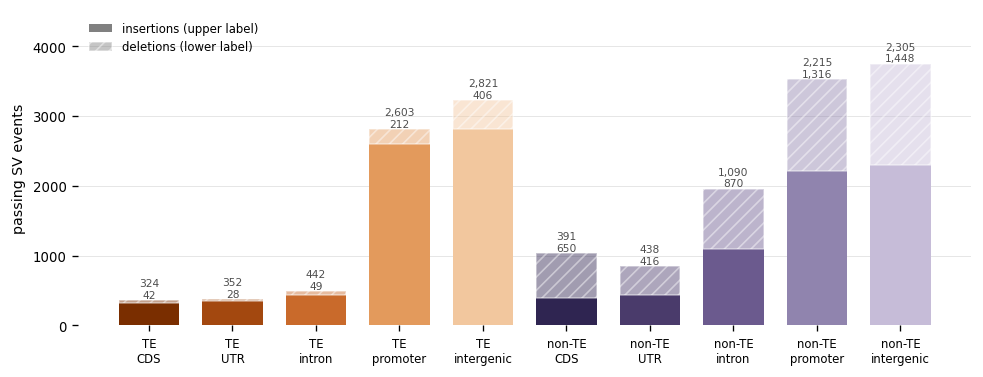

kind                          del   ins  total
TE content · CDS               42   324    366
TE content · UTR               28   352    380
TE content · intron            49   442    491
TE content · promoter         212  2603   2815
TE content · intergenic       406  2821   3227
non-TE content · CDS          650   391   1041
non-TE content · UTR          416   438    854
non-TE content · intron       870  1090   1960
non-TE content · promoter    1316  2215   3531
non-TE content · intergenic  1448  2305   3753

total passing events: 18,418 (the reported model's 18,418)


In [3]:

CAT=pd.read_csv(f"{G}/sv_event_catalog.csv"); EVC=pd.read_csv(f"{G}/graffite/sv_repeat_class_events.csv")
A=CAT[CAT.passes].merge(EVC[["rep_key","cargo"]],left_on="key",right_on="rep_key")
A["cont"]=np.where(A.cargo.isin(["te_full","te_most"]),"TE","nTE")
A["loc"]=np.select([A.L_CDS,A.L_UTR,A.L_intron,A.L_promoter],["cds","utr","intron","promoter"],"intergenic")
A["cls"]="sv_"+A.cont+A["loc"]
n=pd.crosstab(A.cls,A.kind).reindex(CT).fillna(0).astype(int)
fig,a=plt.subplots(figsize=(9.6,3.4)); style(a,axis="y"); x=np.arange(len(CT))
a.bar(x,n["ins"],color=[COL(t) for t in CT],width=0.72,label="insertions")
a.bar(x,n["del"],bottom=n["ins"],color=[COL(t) for t in CT],width=0.72,alpha=0.45,hatch="///",
      edgecolor="white",label="deletions")
for i,t in enumerate(CT):
    a.annotate(f"{n.loc[t,'ins']:,}\n{n.loc[t,'del']:,}",xy=(i,n.loc[t].sum()),ha="center",va="bottom",
               fontsize=6.4,color="0.3")
a.set_xticks(x); a.set_xticklabels([LAB(t).replace(" content · ","\n") for t in CT],fontsize=7)
a.set_ylabel("passing SV events",fontsize=8.5); a.set_ylim(0,1.2*n.sum(1).max())
from matplotlib.patches import Patch
a.legend(handles=[Patch(facecolor="0.5",label="insertions (upper label)"),
                  Patch(facecolor="0.5",alpha=0.45,hatch="///",edgecolor="white",label="deletions (lower label)")],
         fontsize=7,frameon=False,loc="upper left")
save(fig,"cargo_burden_counts",nb=True); plt.show()
t=n.assign(total=n.sum(1)); t.index=[LAB(i) for i in t.index]
print(t.to_string()); print(f"\ntotal passing events: {int(n.values.sum()):,} (the reported model's 18,418)")


## 2 · How separable are the ten burdens?

Correlation across the 231 founders between the ten standardised burdens, and each predictor's variance
inflation factor within the model's fixed effects. A VIF of 10 means the coefficient's variance is ten
times what it would be with an uncorrelated predictor. The reported six-context model has the same
problem (its VIFs are listed for reference), for the same reason: every burden tracks overall divergence
from Col-0.

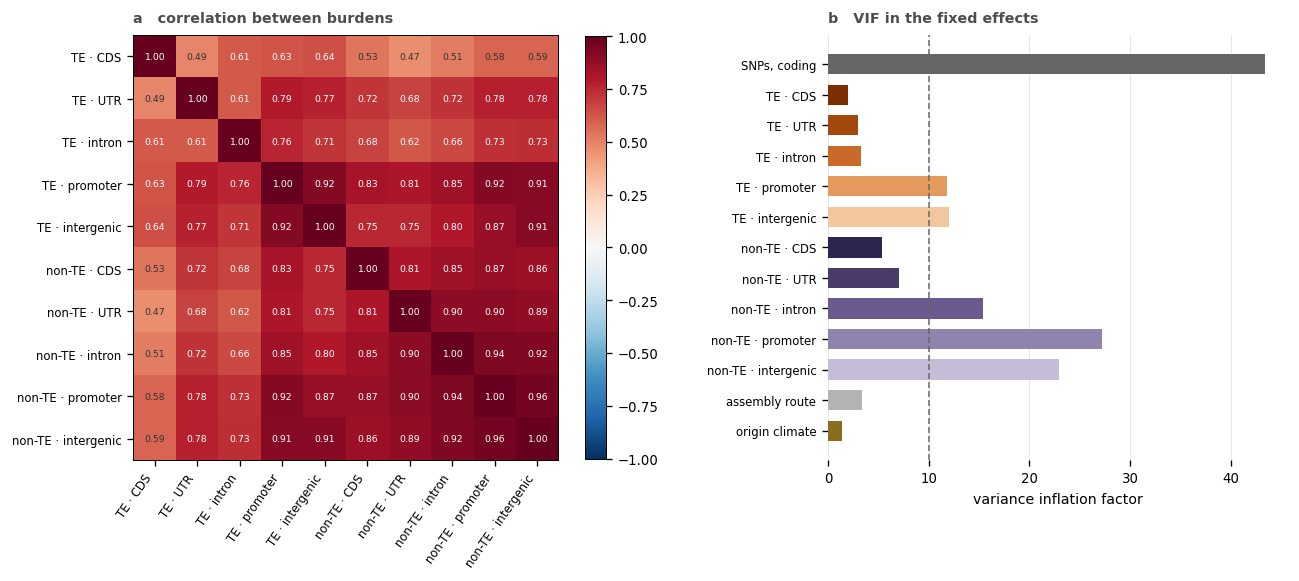

VIF, cargo model:
snp_CDS             43.4
sv_TEcds             1.9
sv_TEutr             3.0
sv_TEintron          3.2
sv_TEpromoter       11.8
sv_TEintergenic     12.1
sv_nTEcds            5.3
sv_nTEutr            7.1
sv_nTEintron        15.4
sv_nTEpromoter      27.2
sv_nTEintergenic    23.0
cactus               3.3
obio1c               1.4

VIF, reported six-context model:
snp_CDS          33.9
cactus            3.1
sv_CDS            5.5
sv_UTR            8.9
sv_intron        16.5
sv_TE            10.9
sv_promoter      25.6
sv_intergenic    21.8
obio1c            1.2


In [4]:

FB=pd.read_csv(f"{G}/founder_burden_event_cargo.csv",dtype={"founder":str})
Z=pd.DataFrame({t:(FB[f"ins_all_{t[3:]}_all"]+FB[f"del_all_{t[3:]}_all"])/
                  (FB[f"called_ins_all_{t[3:]}_all"]+FB[f"called_del_all_{t[3:]}_all"]) for t in CT})
Z=(Z-Z.mean())/Z.std()
LG=pd.read_csv(f"{G}/onestage_all/long.csv",dtype={"founder":str}).drop_duplicates("founder").set_index("founder")
Z.index=FB.founder; Z=Z.join(LG[["snp_CDS","cactus"]]); Z["obio1c"]=FB.set_index("founder").bio1
Cm=Z[CT].corr()
fig,axs=plt.subplots(1,2,figsize=(13,4.6),gridspec_kw=dict(wspace=0.45,width_ratios=[1.15,1]))
a=axs[0]; im=a.imshow(Cm.values,cmap="RdBu_r",vmin=-1,vmax=1)
a.set_xticks(range(len(CT))); a.set_yticks(range(len(CT)))
lab=[LAB(t).replace(" content · "," · ") for t in CT]
a.set_xticklabels(lab,rotation=55,ha="right",fontsize=7); a.set_yticklabels(lab,fontsize=7)
for i in range(len(CT)):
    for j in range(len(CT)):
        a.text(j,i,f"{Cm.values[i,j]:.2f}",ha="center",va="center",fontsize=5.6,
               color="white" if abs(Cm.values[i,j])>0.6 else "0.2")
plt.colorbar(im,ax=a,fraction=0.04)
a.annotate("a   correlation between burdens",xy=(0,1.03),xycoords="axes fraction",fontsize=8.6,fontweight="bold",color="0.3")
P=Z[["snp_CDS"]+CT+["cactus","obio1c"]].astype(float); P=(P-P.mean())/P.std()
vif=pd.Series(np.diag(np.linalg.inv(np.corrcoef(P.values.T))),index=P.columns)
a=axs[1]; style(a,axis="x"); y=np.arange(len(vif))[::-1]
a.barh(y,vif.values,color=["0.4"]+[COL(t) for t in CT]+["0.7","#8C6D1F"],height=0.66)
a.axvline(10,color="0.4",lw=0.9,ls=(0,(4,2)))
a.set_yticks(y); a.set_yticklabels(["SNPs, coding"]+lab+["assembly route","origin climate"],fontsize=7)
a.set_xlabel("variance inflation factor",fontsize=8.5)
a.annotate("b   VIF in the fixed effects",xy=(0,1.03),xycoords="axes fraction",fontsize=8.6,fontweight="bold",color="0.3")
save(fig,"cargo_burden_collinearity",nb=True); plt.show()
print("VIF, cargo model:"); print(vif.round(1).to_string())
R6=LG[["snp_CDS","cactus"]].copy()
FR=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str}).set_index("founder")
for c in ["CDS","UTR","intron","TE","promoter","intergenic"]:
    R6[f"sv_{c}"]=(FR[f"ins_all_{c}_all"]+FR[f"del_all_{c}_all"])/(FR[f"called_ins_all_{c}_all"]+FR[f"called_del_all_{c}_all"])
R6["obio1c"]=FR.bio1; R6=(R6-R6.mean())/R6.std()
print("\nVIF, reported six-context model:")
print(pd.Series(np.diag(np.linalg.inv(np.corrcoef(R6.values.T))),index=R6.columns).round(1).to_string())


## 3 · The burden effects

Each burden's effect at a garden of **average temperature** (13.5 °C; `bio1c` is centred), in % fitness
per carried event and as the fitted coefficient per SD of the burden, 95% CI. Filled markers: Wald
p < 0.05. Below, the reported model's six location contexts, for comparison.

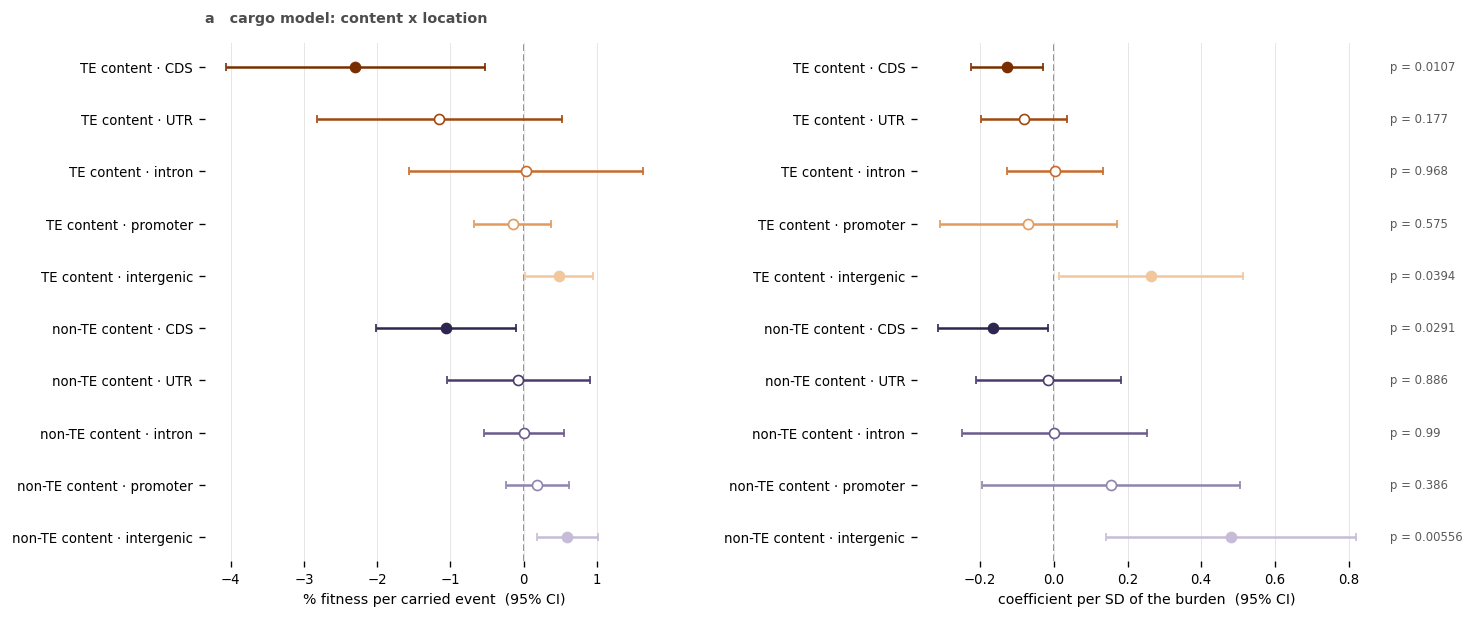

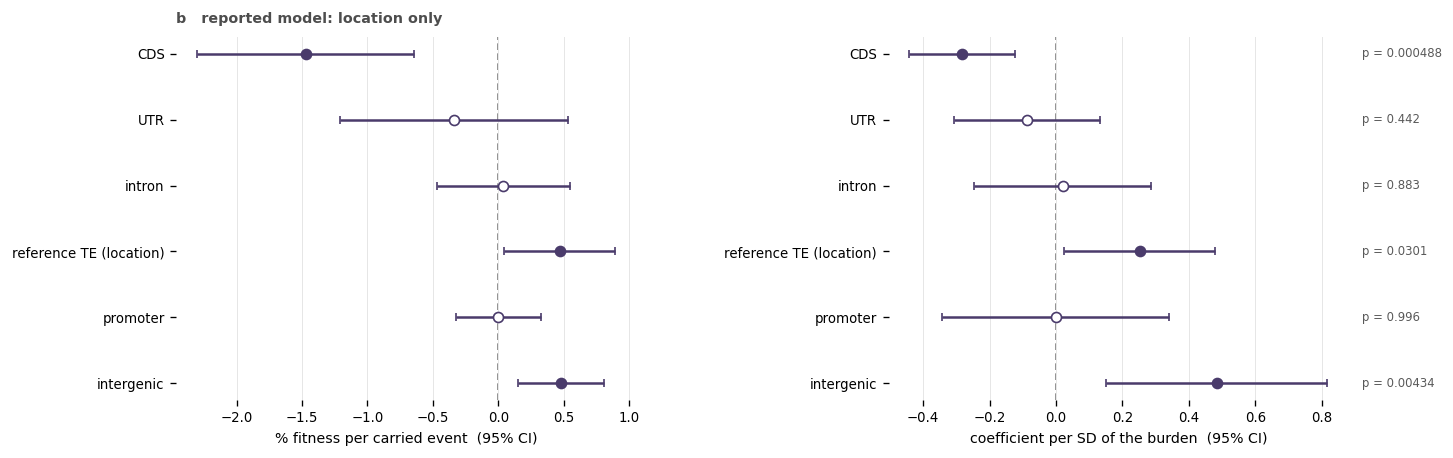

BURDEN EFFECTS at an average-temperature garden (cargo model)

                       term  events_per_SD  pct_per_event   ci_lo   ci_hi  beta_SD       z      p
           TE content · CDS            5.5        -2.3033 -4.0717 -0.5348  -0.1264 -2.5527 0.0107
           TE content · UTR            7.0        -1.1540 -2.8277  0.5197  -0.0808 -1.3514 0.1766
        TE content · intron            8.1         0.0329 -1.5676  1.6333   0.0027  0.0402 0.9679
      TE content · promoter           45.6        -0.1506 -0.6765  0.3754  -0.0686 -0.5610 0.5748
    TE content · intergenic           54.6         0.4832  0.0235  0.9429   0.2637  2.0602 0.0394
       non-TE content · CDS           15.6        -1.0609 -2.0135 -0.1083  -0.1657 -2.1827 0.0291
       non-TE content · UTR           20.0        -0.0718 -1.0531  0.9095  -0.0144 -0.1433 0.8860
    non-TE content · intron           46.5         0.0035 -0.5374  0.5443   0.0016  0.0126 0.9900
  non-TE content · promoter           82.3         0.18

In [5]:

def forest(terms,co,pvf,suffix,fname,lab=LAB,col=COL,title=""):
    fig,axs=plt.subplots(1,2,figsize=(12.6,0.42*len(terms)+1.4),gridspec_kw=dict(wspace=0.55))
    yy=np.arange(len(terms))[::-1]*1.0
    for ax,mode,xl in ((axs[0],"pv","% fitness per carried event  (95% CI)"),
                       (axs[1],"sd","coefficient per SD of the burden  (95% CI)")):
        style(ax); ax.axvline(0,color="0.5",lw=1,ls=(0,(4,2)),zorder=0)
        for k,t in enumerate(terms):
            n=t+suffix; kf=pvf(t) if mode=="pv" else 1.0
            e,se,p=co.loc[n,"estimate"]*kf,co.loc[n,"se"]*kf,co.loc[n,"p"]
            ax.errorbar(e,yy[k],xerr=1.96*se,fmt="o",ms=6,lw=1.5,capsize=2.5,color=col(t),
                        markerfacecolor=col(t) if p<0.05 else "white",zorder=3)
        ax.set_yticks(yy); ax.set_yticklabels([lab(t) for t in terms],fontsize=8); ax.set_xlabel(xl,fontsize=8.5)
    for k,t in enumerate(terms):
        axs[1].annotate(f"p = {co.loc[t+suffix,'p']:.3g}",xy=(1.03,yy[k]),xycoords=("axes fraction","data"),
                        ha="left",va="center",fontsize=7,color="0.35")
    if title: axs[0].annotate(title,xy=(0,1.04),xycoords="axes fraction",fontsize=8.6,fontweight="bold",color="0.3")
    save(fig,fname,nb=True); plt.show()
forest(CT,CO,PV,"","cargo_burden_main",title="a   cargo model: content x location")
R6T=["sv_CDS","sv_UTR","sv_intron","sv_TE","sv_promoter","sv_intergenic"]
L6={"sv_CDS":"CDS","sv_UTR":"UTR","sv_intron":"intron","sv_TE":"reference TE (location)","sv_promoter":"promoter",
    "sv_intergenic":"intergenic"}
forest(R6T,COR,lambda t:100/VPR[t.split(":")[0]],"","cargo_burden_main_reported",
       lab=lambda t:L6[t],col=lambda t:"#4A3B6B",title="b   reported model: location only")
rows=[]
for t in CT:
    rows.append(dict(term=LAB(t),events_per_SD=round(VPS[t],1),pct_per_event=CO.loc[t,"estimate"]*PV(t),
                     ci_lo=(CO.loc[t,"estimate"]-1.96*CO.loc[t,"se"])*PV(t),ci_hi=(CO.loc[t,"estimate"]+1.96*CO.loc[t,"se"])*PV(t),
                     beta_SD=CO.loc[t,"estimate"],z=CO.loc[t,"z"],p=CO.loc[t,"p"]))
print("BURDEN EFFECTS at an average-temperature garden (cargo model)\n")
print(pd.DataFrame(rows).round(4).to_string(index=False))


## 4 · How the effects change with garden temperature

Each burden's interaction with garden temperature: the change in its effect per °C of garden mean
annual temperature, with Wald and likelihood-ratio p-values (the LRT drops that one interaction from the
ML fit, 1 df).

⚠ **Provisional.** These p-values are anti-conservative. The reported notebook's permutation null showed
the null SD of z for these terms runs 0.99–1.26 instead of 1, because the garden slopes sit at the variance
boundary. That permutation has not been run for this model. Read anything near p = 0.05 as not
established.

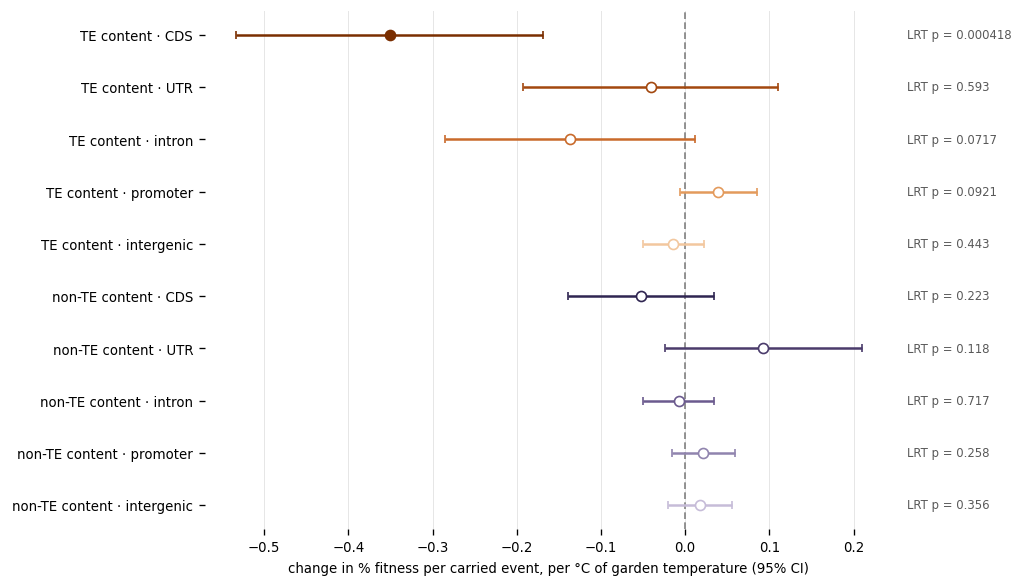

BURDEN x GARDEN TEMPERATURE (provisional p-values)

                       term  pct_per_event_per_degC  beta_SD_per_degC       z  wald_p  LRT_p
           TE content · CDS                 -0.3508           -0.0193 -3.7668  0.0002 0.0004
           TE content · UTR                 -0.0411           -0.0029 -0.5338  0.5935 0.5934
        TE content · intron                 -0.1364           -0.0111 -1.8010  0.0717 0.0717
      TE content · promoter                  0.0394            0.0180  1.6844  0.0921 0.0921
    TE content · intergenic                 -0.0141           -0.0077 -0.7599  0.4473 0.4434
       non-TE content · CDS                 -0.0526           -0.0082 -1.1928  0.2330 0.2233
       non-TE content · UTR                  0.0925            0.0185  1.5521  0.1206 0.1185
    non-TE content · intron                 -0.0079           -0.0037 -0.3628  0.7167 0.7167
  non-TE content · promoter                  0.0217            0.0179  1.1248  0.2607 0.2582
non-TE content · i

In [6]:

TI=[f"{t}:bio1c" for t in CT]
fig,a=plt.subplots(figsize=(7.4,0.42*len(CT)+1.4)); style(a); a.axvline(0,color="0.5",lw=1,ls=(0,(4,2)))
yy=np.arange(len(CT))[::-1]
for k,t in enumerate(CT):
    e,se=CO.loc[f"{t}:bio1c","estimate"]*PV(t),CO.loc[f"{t}:bio1c","se"]*PV(t)
    a.errorbar(e,yy[k],xerr=1.96*se,fmt="o",ms=6,lw=1.5,capsize=2.5,color=COL(t),
               markerfacecolor=COL(t) if LRT[t]<0.05 else "white")
    a.annotate(f"LRT p = {LRT[t]:.3g}",xy=(1.02,yy[k]),xycoords=("axes fraction","data"),fontsize=7,color="0.35",va="center")
a.set_yticks(yy); a.set_yticklabels([LAB(t) for t in CT],fontsize=8)
a.set_xlabel("change in % fitness per carried event, per °C of garden temperature (95% CI)",fontsize=8)
save(fig,"cargo_burden_interactions",nb=True); plt.show()
rows=[dict(term=LAB(t),pct_per_event_per_degC=CO.loc[f"{t}:bio1c","estimate"]*PV(t),
           beta_SD_per_degC=CO.loc[f"{t}:bio1c","estimate"],z=CO.loc[f"{t}:bio1c","z"],
           wald_p=CO.loc[f"{t}:bio1c","p"],LRT_p=LRT[t]) for t in CT]
print("BURDEN x GARDEN TEMPERATURE (provisional p-values)\n"); print(pd.DataFrame(rows).round(4).to_string(index=False))


## 5 · The questions this model was built for

Contrasts between coefficients of the **same fit**, on the per-carried-event scale, with SEs from the
fitted covariance matrix (`vcov`), so the correlation between the two estimates is accounted for.

- **TE vs non-TE at the same location.** Does an event that adds or removes TE sequence in a promoter
  cost more or less than one that adds or removes other sequence there? This is the content question
  directly, and it compares two burdens that share a location, so collinearity hurts it less than single
  coefficients.
- **TE in promoters vs TE in intergenic sequence.** Does TE content matter more next to a gene?

Each is tested for the main effect (average-temperature garden) and for the temperature interaction. The
interaction contrasts inherit the caveat of §4.

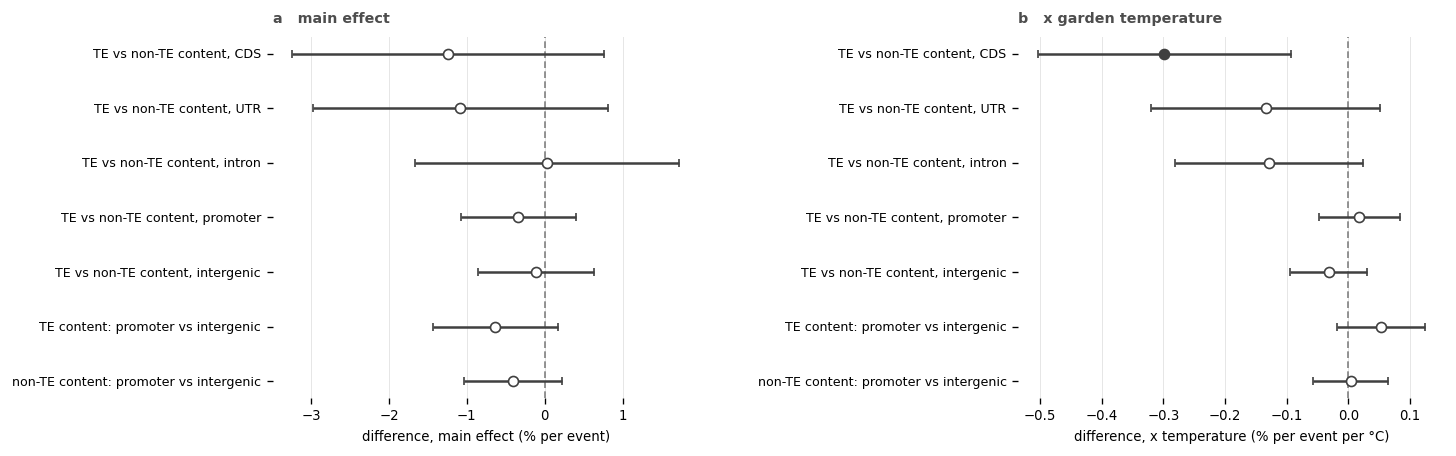

CONTRASTS (first minus second; filled = p < 0.05)

                              contrast                           quantity  difference     se   ci_lo   ci_hi      p
             TE vs non-TE content, CDS          main effect (% per event)     -1.2424 1.0216 -3.2447  0.7600 0.2240
             TE vs non-TE content, CDS x temperature (% per event per °C)     -0.2983 0.1049 -0.5038 -0.0927 0.0045
             TE vs non-TE content, UTR          main effect (% per event)     -1.0823 0.9655 -2.9747  0.8102 0.2623
             TE vs non-TE content, UTR x temperature (% per event per °C)     -0.1337 0.0948 -0.3195  0.0521 0.1584
          TE vs non-TE content, intron          main effect (% per event)      0.0294 0.8665 -1.6690  1.7278 0.9729
          TE vs non-TE content, intron x temperature (% per event per °C)     -0.1285 0.0775 -0.2804  0.0234 0.0974
        TE vs non-TE content, promoter          main effect (% per event)     -0.3388 0.3771 -1.0779  0.4004 0.3690
        TE vs non-TE 

In [7]:

def contrast(t1,t2,suffix=""):
    n1,n2=t1+suffix,t2+suffix; a1,a2=PV(t1),PV(t2)
    e=a1*CO.loc[n1,"estimate"]-a2*CO.loc[n2,"estimate"]
    v=a1**2*VV.loc[n1,n1]+a2**2*VV.loc[n2,n2]-2*a1*a2*VV.loc[n1,n2]
    se=np.sqrt(v); return e,se,2*stats.norm.sf(abs(e/se))
PAIRS=[(f"sv_TE{l}",f"sv_nTE{l}",f"TE vs non-TE content, {LOCN[l]}") for l in LOCS]+\
      [("sv_TEpromoter","sv_TEintergenic","TE content: promoter vs intergenic"),
       ("sv_nTEpromoter","sv_nTEintergenic","non-TE content: promoter vs intergenic")]
rows=[]
for t1,t2,lab in PAIRS:
    for suf,what in (("","main effect (% per event)"),(":bio1c","x temperature (% per event per °C)")):
        e,se,p=contrast(t1,t2,suf); rows.append(dict(contrast=lab,quantity=what,difference=e,se=se,
                                                     ci_lo=e-1.96*se,ci_hi=e+1.96*se,p=p))
R=pd.DataFrame(rows)
fig,axs=plt.subplots(1,2,figsize=(12.6,3.9),gridspec_kw=dict(wspace=0.75))
for a,(what,L) in zip(axs,[("main effect (% per event)","a   main effect"),("x temperature (% per event per °C)","b   x garden temperature")]):
    style(a); a.axvline(0,color="0.5",lw=1,ls=(0,(4,2))); d=R[R.quantity==what].reset_index(drop=True)
    yy=np.arange(len(d))[::-1]
    for k,r in d.iterrows():
        a.errorbar(r.difference,yy[k],xerr=1.96*r.se,fmt="o",ms=6,lw=1.5,capsize=2.5,color="0.25",
                   markerfacecolor="0.25" if r.p<0.05 else "white")
    a.set_yticks(yy); a.set_yticklabels(d.contrast,fontsize=7.6); a.set_xlabel(f"difference, {what}",fontsize=8)
    a.annotate(L,xy=(0,1.04),xycoords="axes fraction",fontsize=8.6,fontweight="bold",color="0.3")
save(fig,"cargo_burden_contrasts",nb=True); plt.show()
print("CONTRASTS (first minus second; filled = p < 0.05)\n"); print(R.round(4).to_string(index=False))


## 6 · Does content improve the model?

Both models are fitted by maximum likelihood on the same 7,161 rows with the same response and
covariates, so their AICs compare directly. The cargo model spends more parameters: four more burdens,
each with an interaction and a random garden slope. It earns them only if its log-likelihood rises by
more than that cost.

In [8]:

a=ll(PA,"M2p_ml",SUF); b=ll(PR,"M2p_ml",SUFR)
T=pd.DataFrame([dict(model="reported: location only (6 burdens)",logLik=b.logLik,df=int(b.df),AIC=2*b.df-2*b.logLik,singular=b.singular),
                dict(model="cargo: content x location (10 burdens)",logLik=a.logLik,df=int(a.df),AIC=2*a.df-2*a.logLik,singular=a.singular)])
T["dAIC_vs_reported"]=T.AIC-T.AIC.iloc[0]
print(T.round(2).to_string(index=False))
print(f"\nthe cargo model has {int(a.df-b.df)} more parameters; its log-likelihood is {a.logLik-b.logLik:+.2f} higher")


                                 model    logLik  df      AIC  singular  dAIC_vs_reported
   reported: location only (6 burdens) -11038.73  27 22131.45      True              0.00
cargo: content x location (10 burdens) -11017.20  39 22112.40      True            -19.05

the cargo model has 12 more parameters; its log-likelihood is +21.53 higher


## 7 · Variance components

Random-effect variances of the REML fit. A random garden slope near zero sits at the boundary; with ten
slopes several are expected there, which is what makes the fit singular. The reported six-context model
is also singular.

In [9]:

v=VC.copy(); v["label"]=[(LAB(x) if isinstance(x,str) and x.startswith("sv_") else x) for x in v.var1]
print(v[["grp","label","vcov"]].to_string(index=False)); print(f"\nsingular: {LLR.singular}")


      grp                       label     vcov
      kin                 (Intercept) 0.251996
   garden                      obio1c 0.008891
 garden.1 non-TE content · intergenic 0.012198
 garden.2   non-TE content · promoter 0.019954
 garden.3     non-TE content · intron 0.000000
 garden.4        non-TE content · UTR 0.038455
 garden.5        non-TE content · CDS 0.000002
 garden.6     TE content · intergenic 0.002057
 garden.7       TE content · promoter 0.000000
 garden.8         TE content · intron 0.003929
 garden.9            TE content · UTR 0.000000
garden.10            TE content · CDS 0.003430
garden.11                 (Intercept) 0.253620
 Residual                         NaN 1.142568

singular: True


## 8 · Reading it

**Coding SVs are costly whatever they carry.** Both CDS burdens are negative at an average-temperature
garden: TE content −2.30% per event (95% CI −4.07 to −0.53, p = 0.011) and non-TE content −1.06% (−2.01 to
−0.11, p = 0.029). The reported model's single coding term is −1.47% (p = 5 × 10⁻⁴). The TE vs non-TE
difference in CDS is not significant (−1.24 percentage points, p = 0.22). Content does not change *whether*
coding SVs are deleterious.

**The coding × temperature interaction sits in TE-content coding SVs.** Their cost rises by 0.35% per
event per °C of garden temperature (Wald p = 2 × 10⁻⁴, LRT p = 4 × 10⁻⁴). For non-TE coding SVs it is
0.05% per °C (p = 0.23), and the TE minus non-TE difference is p = 0.0045. The reported model's coding ×
temperature term (−0.12% per °C) is a blend of the two. Three reasons to hold this loosely:
- these p-values are the model's own; the reported model's permutation null for its coding interaction
  had an SD of z of 1.09, and if that applied here the TE-CDS interaction would still be about
  p ≈ 5 × 10⁻⁴ and the contrast about p ≈ 0.01, but that is an extrapolation, not a test;
- TE content in CDS is the smallest class, 366 events (324 insertions), only 5.5 events per SD of the
  burden, so a few events drive it;
- whether these are TE sequence landing in genes or TE-gene annotations counted as CDS has not been
  checked.

**TE in promoters: nothing.** TE-content promoter SVs have no effect (−0.15% per event, p = 0.57), no
temperature dependence (p = 0.09), and do not differ from non-TE promoter SVs (main effect p = 0.37,
interaction p = 0.60). TE content in promoters does not differ from TE content in intergenic sequence
either (p = 0.12). So the TE-into-promoter hypothesis gets no support here, with insertions and deletions
pooled and counted as differences from Col-0.

**Intergenic burdens stay positive for both contents** (TE +0.48% per event, p = 0.039; non-TE +0.60%,
p = 0.006), matching the reported model's positive intergenic and reference-TE terms. Content does not
explain them.

**The cargo model fits better.** ΔAIC = −19 against the reported model on the same rows. It spends 12 more
parameters and raises the log-likelihood by 21.5. Most of that plausibly comes from separating the
TE-content coding interaction, but this has not been isolated.

**What would firm this up.**
- The garden-temperature permutation null for this model, as the reported notebook uses.
- A check of what the 366 TE-content CDS events are (TE genes, nested insertions, replacements).
- A reduced model with only the CDS term split by content, to see whether that alone carries the AIC
  gain.

## As run

1. `_sv_burden_cargo_build.py` (env kmate): founder burdens by content × location per direction, Truvari
   events, ≥ 90% founder call rate, ≥ 2 carriers, origins `all` and `shared` →
   `results/sv_adaptive/founder_burden_cargo.csv`. Asserts the pass filter equals the catalog's `passes`
   for every event.
2. `_sv_burden_cargo_export.py`: renames the classes into the model's column convention
   (`{ins,del}_<origin>_<class>_all`) → `founder_burden_event_cargo.csv`. Asserts that, per founder, carried
   and called totals over the ten classes equal the reported table's totals over its six contexts.
3. `_submit_cargo_burden.sh` → `_sv_burden_pooled_models.R` with `POOL_SET=cargo10 INTER_SET=all
   BURDEN_FILE=founder_burden_event_cargo.csv` and the reported model's settings (`BURDEN_ORIGIN=all
   ONESTAGE_DIR=onestage_all EXTRA_FIXED="obio1c + obio1c:bio1c" EXTRA_RE="(0 + obio1c | garden)"
   RE_DROP=fid BURDEN_MODE=rate`). Tasks 0 M1p_reml, 1 M2p_reml, 2 M2p_ml, 3–12 M2p_ml_drop_<term>.
4. This notebook: `_build_sv_burden_cargo_nb.py`.

Not run: the garden-temperature permutation null for the interactions (the reported model's
`perm/` set), the equalised-count refits, and the jackknife / trimming diagnostics.